<a href="https://colab.research.google.com/github/jayankishore/732224ai045-Jayankishore-GB/blob/main/MovieReview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

# Load the dataset
file_path = '/content/Data_Test.xlsx'
df = pd.read_excel(file_path)

# Display basic information and the first few rows
print(df.info())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2748 entries, 0 to 2747
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   STORY   2748 non-null   object
dtypes: object(1)
memory usage: 21.6+ KB
None


,STORY
0,2019 will see gadgets like gaming smartphones ...
1,It has also unleashed a wave of changes in the...
2,It can be confusing to pick the right smartpho...
3,The mobile application is integrated with a da...
4,We have rounded up some of the gadgets that sh...


In [5]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Download NLTK stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

# Download the IMDB dataset
url = 'https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv'
df_imdb = pd.read_csv(url)

# Let's inspect class distribution and sample 2,500 positive and 2,500 negative reviews
print("Original dataset shape:", df_imdb.shape)
print(df_imdb['sentiment'].value_counts())

df_pos = df_imdb[df_imdb['sentiment'] == 'positive'].sample(n=2500, random_state=42)
df_neg = df_imdb[df_imdb['sentiment'] == 'negative'].sample(n=2500, random_state=42)

df_sampled = pd.concat([df_pos, df_neg]).sample(frac=1, random_state=42).reset_index(drop=True)
print("Sampled dataset shape:", df_sampled.shape)
print(df_sampled['sentiment'].value_counts())

# Clean Text function
def clean_text(text):
    # Remove HTML tags
    text = re.sub(r'<[^>]*>', '', text)
    # Remove non-alphabetical characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Convert to lowercase and split
    words = text.lower().split()
    # Remove stopwords
    words = [w for w in words if w not in stop_words]
    return ' '.join(words)

df_sampled['cleaned_review'] = df_sampled['review'].apply(clean_text)
display(df_sampled[['review', 'cleaned_review', 'sentiment']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Original dataset shape: (50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Sampled dataset shape: (5000, 2)
sentiment
positive    2500
negative    2500
Name: count, dtype: int64


,review,cleaned_review,sentiment
0,"Why would this film be so good, but only gross...",would film good gross estimated award nominati...,positive
1,"The name ""cult movie"" is often given to films ...",name cult movie often given films continue scr...,negative
2,Another stinker from the PM Entertainment grou...,another stinker pm entertainment group thankfu...,negative
3,It really isn't hard to understand this movie!...,really isnt hard understand movie watched expe...,positive
4,"Make no mistake, Maureen O'Sullivan is easily ...",make mistake maureen osullivan easily gorgeous...,positive


In [6]:
# Map sentiments to binary values (1 for positive, 0 for negative)
df_sampled['label'] = df_sampled['sentiment'].map({'positive': 1, 'negative': 0})

# Tokenize text
max_words = 10000
max_len = 150

tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(df_sampled['cleaned_review'])

sequences = tokenizer.texts_to_sequences(df_sampled['cleaned_review'])
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')
labels = df_sampled['label'].values

# Split data: 70% train, 15% validation, 15% testing
X_train_full, X_test, y_train_full, y_test = train_test_split(padded_sequences, labels, test_size=0.15, random_state=42, stratify=labels)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1765, random_state=42, stratify=y_train_full) # 0.1765 of 85% is ~15%

print("Training set shape:", X_train.shape, "Labels:", len(y_train))
print("Validation set shape:", X_val.shape, "Labels:", len(y_val))
print("Testing set shape:", X_test.shape, "Labels:", len(y_test))

Training set shape: (3499, 150) Labels: 3499
Validation set shape: (751, 150) Labels: 751
Testing set shape: (750, 150) Labels: 750


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Define the Sequential Model
# Justification: LSTM is suitable here because it handles the temporal dependency of text data and retains context across sequential elements.
model = Sequential([
    Embedding(input_dim=max_words, output_dim=64, input_length=max_len),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Setup early stopping to avoid overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stop]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 11s 143ms/step - accuracy: 0.4959 - loss: 0.6934 - val_accuracy: 0.5073 - val_loss: 0.6922
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 131ms/step - accuracy: 0.6628 - loss: 0.6301 - val_accuracy: 0.7230 - val_loss: 0.5333
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 143ms/step - accuracy: 0.8582 - loss: 0.3568 - val_accuracy: 0.7896 - val_loss: 0.5233
Epoch 4/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 136ms/step - accuracy: 0.9457 - loss: 0.1675 - val_accuracy: 0.7909 - val_loss: 0.5871
Epoch 5/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 10s 131ms/step - accuracy: 0.9646 - loss: 0.1052 - val_accuracy: 0.7843 - val_loss: 0.6808
Epoch 6/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 142ms/step - accuracy: 0.9857 - loss: 0.0524 - val_accuracy: 0.7830 - val_loss: 0.9126


24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
=== TEST EVALUATION METRICS ===
Accuracy:  0.8053
Precision: 0.8418
Recall:    0.7520
F1-Score:  0.7944



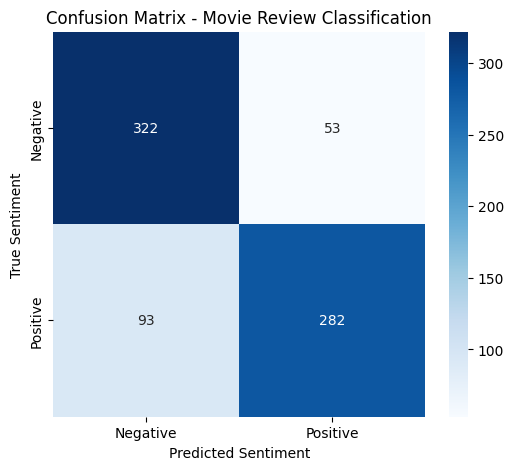

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

Review 1: "I absolutely loved this movie! The characters were brilliant and the plot kept me hooked until the very end."
Predicted Sentiment: Positive (Confidence Score: 0.9852)

Review 2: "What an absolute waste of time. The acting was atrocious and the story made absolutely no sense."
Predicted Sentiment: Positive (Confidence Score: 0.5592)

Review 3: "A masterpiece of modern cinema. Truly moving performances and breathtaking cinematography."
Predicted Sentiment: Positive (Confidence Score: 0.9931)

Review 4: "It was okay, but honestly quite boring at times. Nothing spectacular or memorable."
Predicted Sentiment: Positive (Confidence Score: 0.9311)

Review 5: "Highly disappointing. I expected a thriller, but got a cheesy, predictable comedy instead."
Predicted Sentiment: Positive (Confidence Score: 0.9703)


In [8]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Evaluate the model on the test dataset
predictions_prob = model.predict(X_test)
y_pred = (predictions_prob > 0.5).astype(int).flatten()

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=== TEST EVALUATION METRICS ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix - Movie Review Classification')
plt.ylabel('True Sentiment')
plt.xlabel('Predicted Sentiment')
plt.show()

# Demonstrate sentiment prediction on 5 unseen reviews
unseen_reviews = [
    "I absolutely loved this movie! The characters were brilliant and the plot kept me hooked until the very end.",
    "What an absolute waste of time. The acting was atrocious and the story made absolutely no sense.",
    "A masterpiece of modern cinema. Truly moving performances and breathtaking cinematography.",
    "It was okay, but honestly quite boring at times. Nothing spectacular or memorable.",
    "Highly disappointing. I expected a thriller, but got a cheesy, predictable comedy instead."
]

# Preprocess and clean unseen reviews
cleaned_unseen = [clean_text(r) for r in unseen_reviews]
seqs_unseen = tokenizer.texts_to_sequences(cleaned_unseen)
padded_unseen = pad_sequences(seqs_unseen, maxlen=max_len, padding='post', truncating='post')

# Predict
probs = model.predict(padded_unseen)
for i, (review, prob) in enumerate(zip(unseen_reviews, probs)):
    sentiment = "Positive" if prob > 0.5 else "Negative"
    print(f"\nReview {i+1}: \"{review}\"")
    print(f"Predicted Sentiment: {sentiment} (Confidence Score: {prob[0]:.4f})")